# Stage 2 – Exploratory Data Analysis

Goal: understand the shape of my daily activity before any formal test.
Questions guiding this notebook:
1. What do daily step counts look like overall (distribution, outliers, data quality)?
2. How do the life periods differ in level **and** spread?
3. How does the *shape of the day* (hourly profile) change between jobs and student life?
4. Are there weekday/weekend and long-term trends that could confound comparisons?

All figures are saved to `figures/` so they can be shown in the README.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats
sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)

daily = pd.read_csv("../data/daily_activity.csv", parse_dates=["date"])
hourly = pd.read_csv("../data/hourly_steps.csv", parse_dates=["date"])
# drop the last, incomplete export day
daily = daily[daily.date < "2026-11-17"].copy()

ORDER = ["high_school","exam_prep","pre_semester","semester","finals","holiday",
         "market_job","summer_school_mentor","restaurant_job","travel"]
JOBS = ["market_job","summer_school_mentor","restaurant_job"]
print(daily.shape); daily.head()

(1713, 20)


,date,steps,distance_km,flights,headphone_db,walking_speed_kmh,step_length_cm,first_active_hour,last_active_hour,night_steps,evening_steps,period,semester,country,period_group,is_work,weekday,is_weekend,year,month
0,2022-03-10,3202.0,2.39,4.0,NaN,4.63,75.30,15,16,0.0,24.0,high_school,NaN,Turkey,school,False,Thursday,False,2022,3
1,2022-03-11,11536.0,8.94,19.0,77.78,5.66,85.88,13,22,1.0,4510.0,high_school,NaN,Turkey,school,False,Friday,False,2022,3
2,2022-03-12,294.0,0.20,2.0,78.72,NaN,NaN,11,23,0.0,129.0,high_school,NaN,Turkey,school,False,Saturday,True,2022,3
3,2022-03-13,17116.0,12.61,12.0,78.17,4.67,76.97,10,22,0.0,8504.0,high_school,NaN,Turkey,school,False,Sunday,True,2022,3
4,2022-03-14,9844.0,7.06,15.0,78.60,4.70,76.63,8,21,0.0,4380.0,high_school,NaN,Turkey,school,False,Monday,False,2022,3


## 1. Data quality and sanity checks

In [2]:
print(daily.isna().sum()[lambda s: s>0])
print("days with 0 steps:", (daily.steps==0).sum())
print("date gaps:", (daily.date.diff().dt.days > 1).sum())
daily[["steps","distance_km","flights","walking_speed_kmh","step_length_cm"]].describe().round(1)

flights               20
headphone_db          99
walking_speed_kmh      5
step_length_cm         5
semester             977
dtype: int64
days with 0 steps: 0
date gaps: 0


,steps,distance_km,flights,walking_speed_kmh,step_length_cm
count,1713.0,1713.0,1693.0,1708.0,1708.0
mean,9955.0,7.4,14.3,4.8,76.4
std,4792.4,3.6,9.2,0.4,4.1
min,107.0,0.1,1.0,2.6,47.0
25%,6863.0,5.1,8.0,4.6,74.4
50%,9477.0,7.0,13.0,4.8,76.7
75%,12289.0,9.2,18.0,5.0,78.9
max,38697.0,27.4,72.0,5.8,87.9


Distance and steps should be almost perfectly linked (distance ≈ steps × step length).
A strong correlation is a plausibility check that the export was parsed correctly.

In [3]:
r = daily[["steps","distance_km"]].corr().iloc[0,1]
print(f"Pearson r(steps, distance) = {r:.3f}")

Pearson r(steps, distance) = 0.993


## 2. Distribution of daily steps

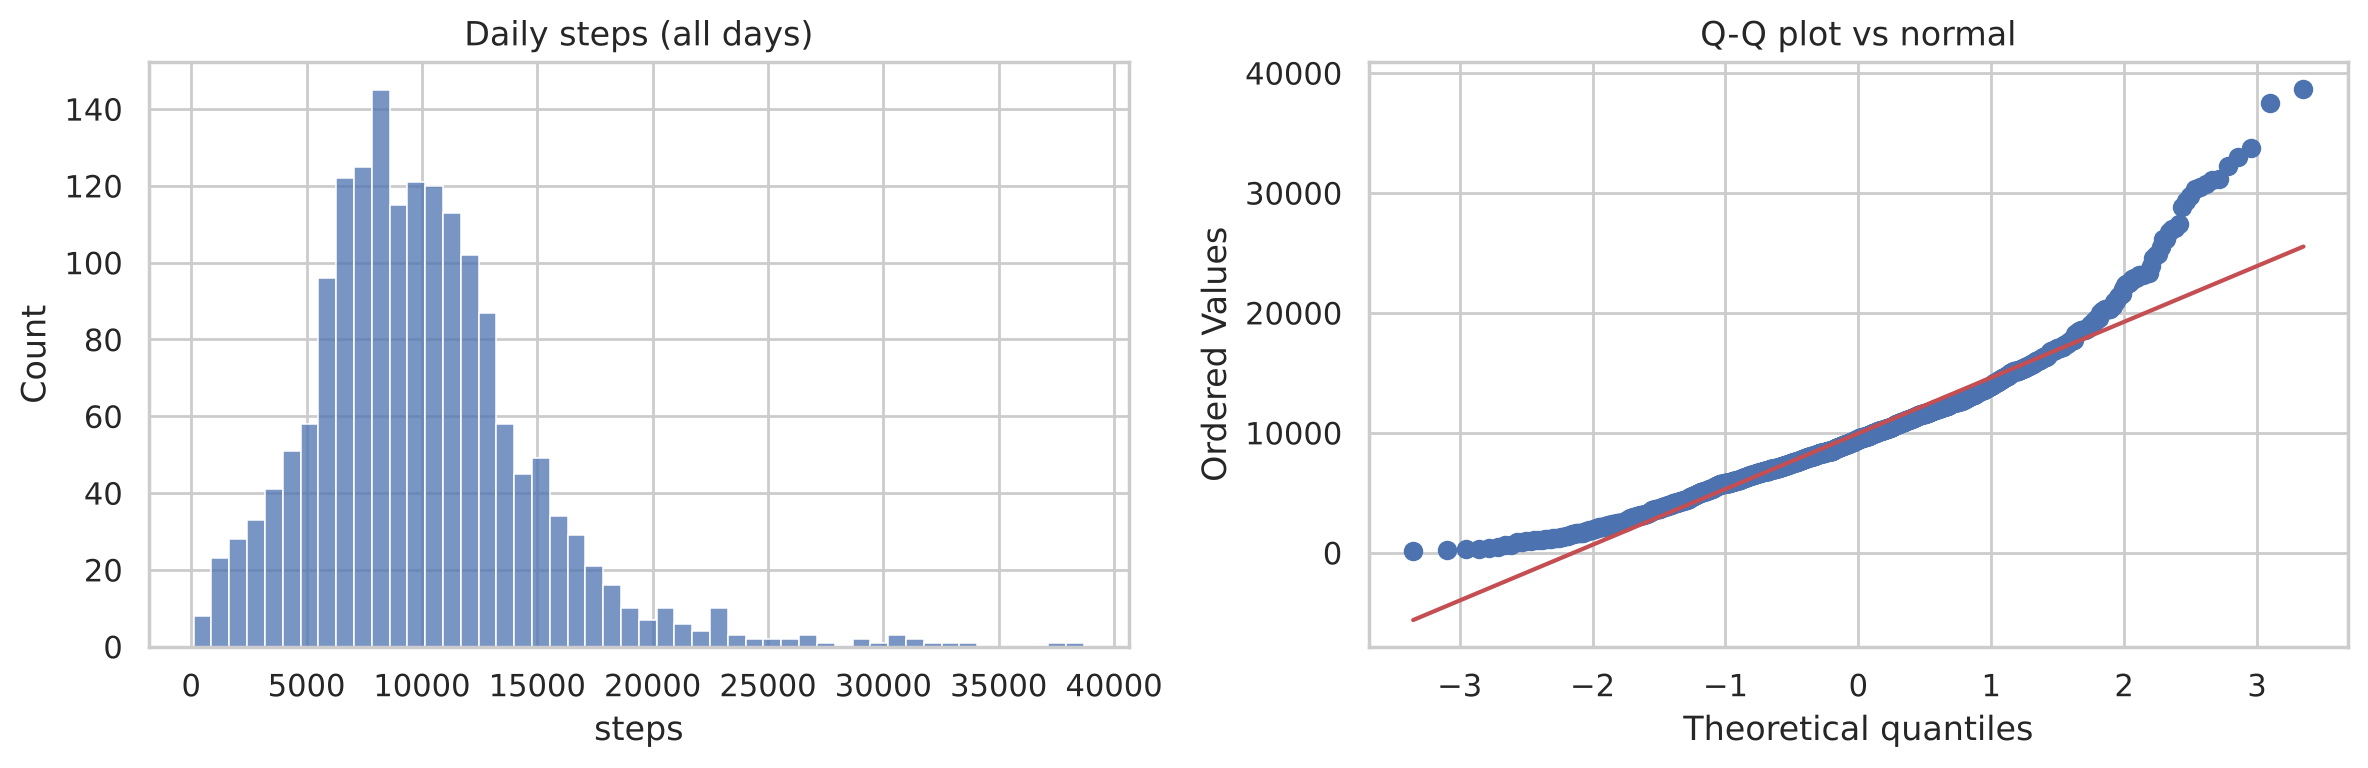

skewness: 1.2  kurtosis: 3.53


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(daily.steps, bins=50, ax=ax[0]); ax[0].set_title("Daily steps (all days)")
stats.probplot(daily.steps, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot vs normal")
plt.tight_layout(); plt.savefig(FIG/"01_steps_distribution.png", dpi=150); plt.show()
print("skewness:", round(stats.skew(daily.steps),2), " kurtosis:", round(stats.kurtosis(daily.steps),2))

Daily steps are right-skewed (a few very active days). This matters later:
a t-test is still reasonable for large groups (CLT), but a non-parametric test
(Mann–Whitney U) should be reported alongside it.

### Outliers (IQR rule)

In [5]:
q1, q3 = daily.steps.quantile([.25,.75]); iqr = q3-q1
out = daily[(daily.steps > q3+1.5*iqr) | (daily.steps < q1-1.5*iqr)]
print(f"{len(out)} outlier days ({len(out)/len(daily):.1%})")
out.period.value_counts()

49 outlier days (2.9%)


period
market_job        26
holiday            7
semester           6
travel             4
high_school        2
restaurant_job     2
exam_prep          1
pre_semester       1
Name: count, dtype: int64

Outliers are kept: they are real days (long shifts, travel), not measurement errors.

## 3. Periods compared

In [6]:
summary = (daily.groupby("period").steps
           .agg(days="count", mean="mean", median="median", std="std")
           .reindex(ORDER).round(0))
summary

,days,mean,median,std
period,,,,
high_school,97,10319.0,9233.0,4804.0
exam_prep,289,8880.0,8905.0,3611.0
pre_semester,42,9775.0,9074.0,4901.0
semester,633,9405.0,9081.0,3546.0
finals,82,8284.0,8185.0,3138.0
holiday,369,9355.0,8996.0,5048.0
market_job,48,21811.0,21799.0,8031.0
summer_school_mentor,40,11436.0,10983.0,3359.0
restaurant_job,93,12456.0,12595.0,3060.0


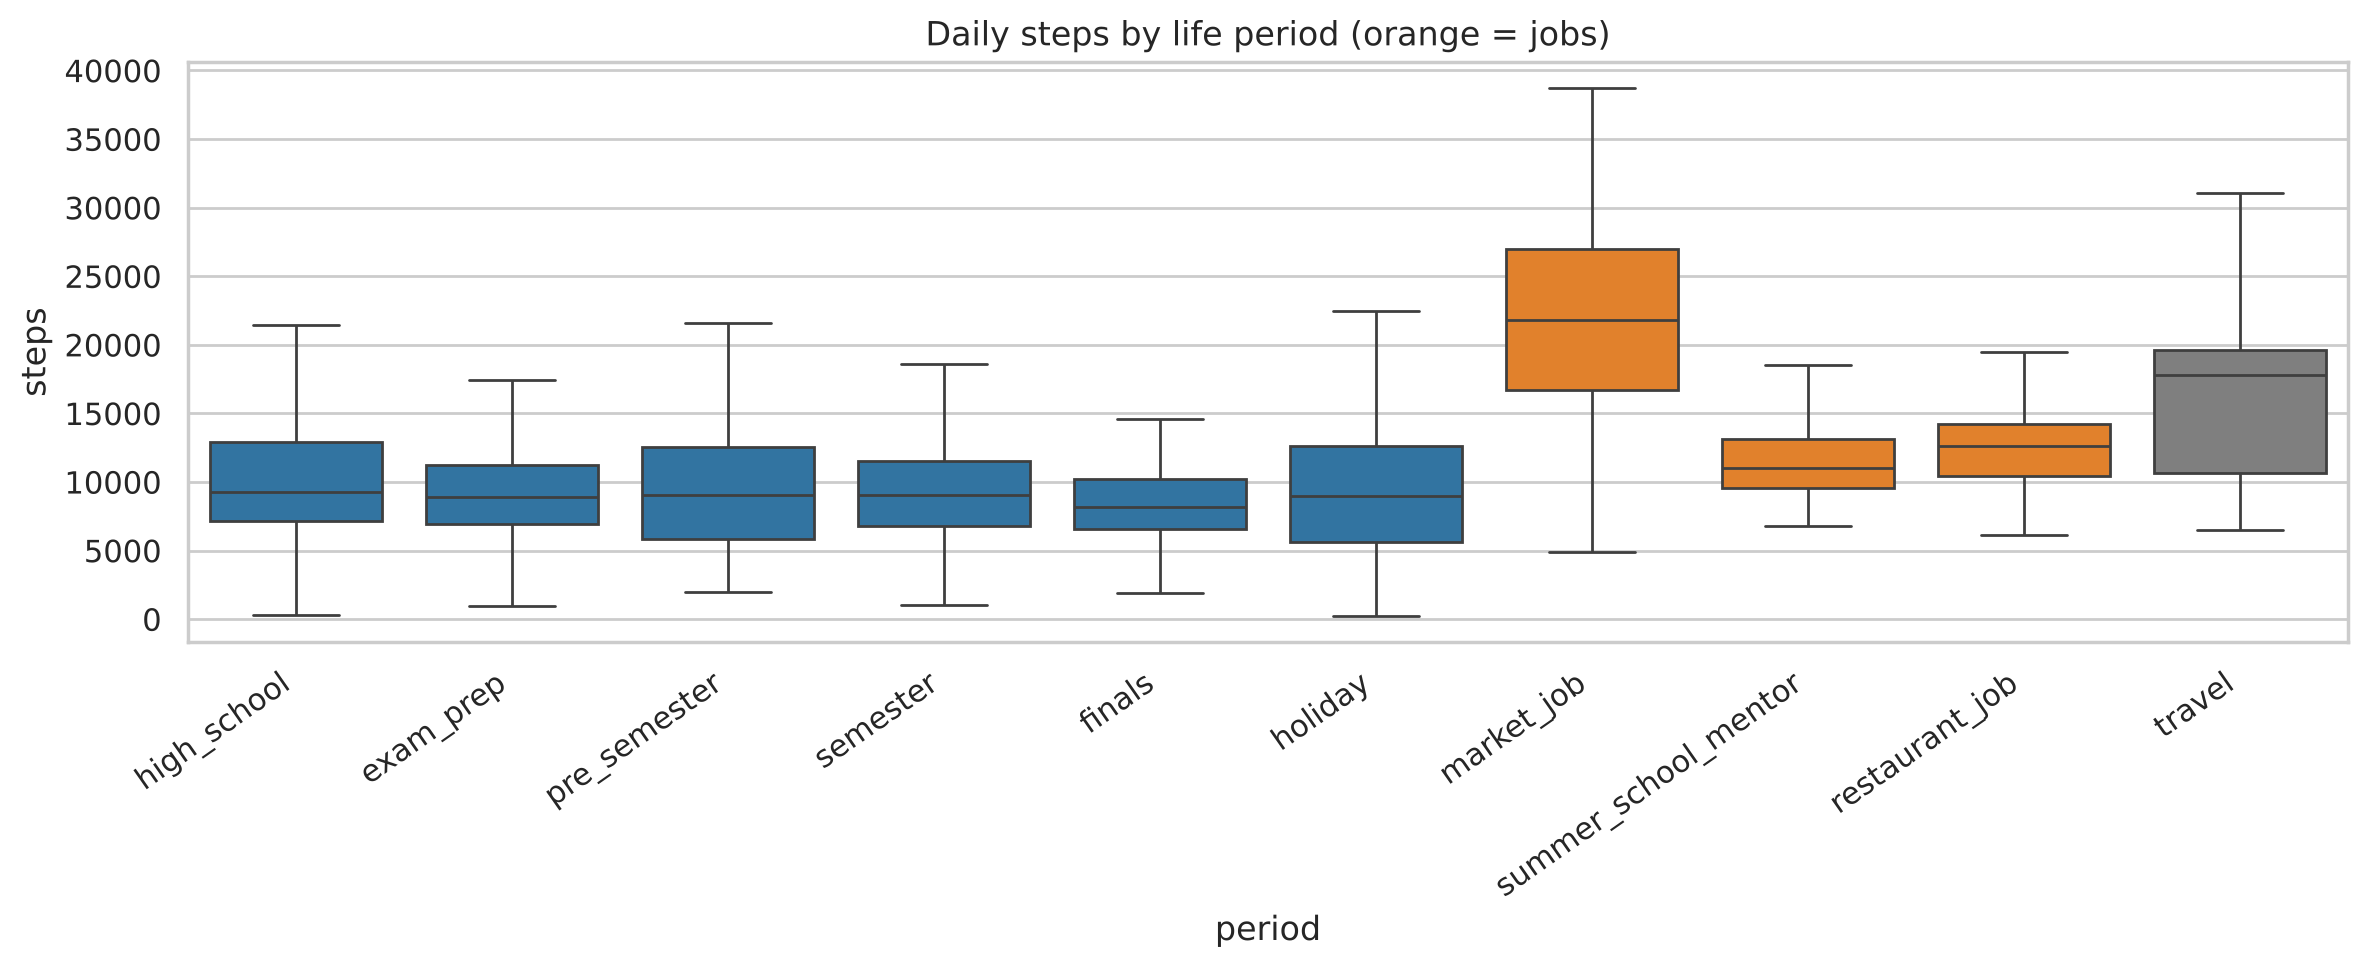

In [7]:
plt.figure(figsize=(12,5))
pal = {p: ("tab:orange" if p in JOBS else "tab:gray" if p=="travel" else "tab:blue") for p in ORDER}
sns.boxplot(data=daily, x="period", y="steps", order=ORDER, hue="period", palette=pal, legend=False, showfliers=False)
plt.xticks(rotation=35, ha="right"); plt.title("Daily steps by life period (orange = jobs)")
plt.tight_layout(); plt.savefig(FIG/"02_steps_by_period.png", dpi=150); plt.show()

## 4. Long-term timeline

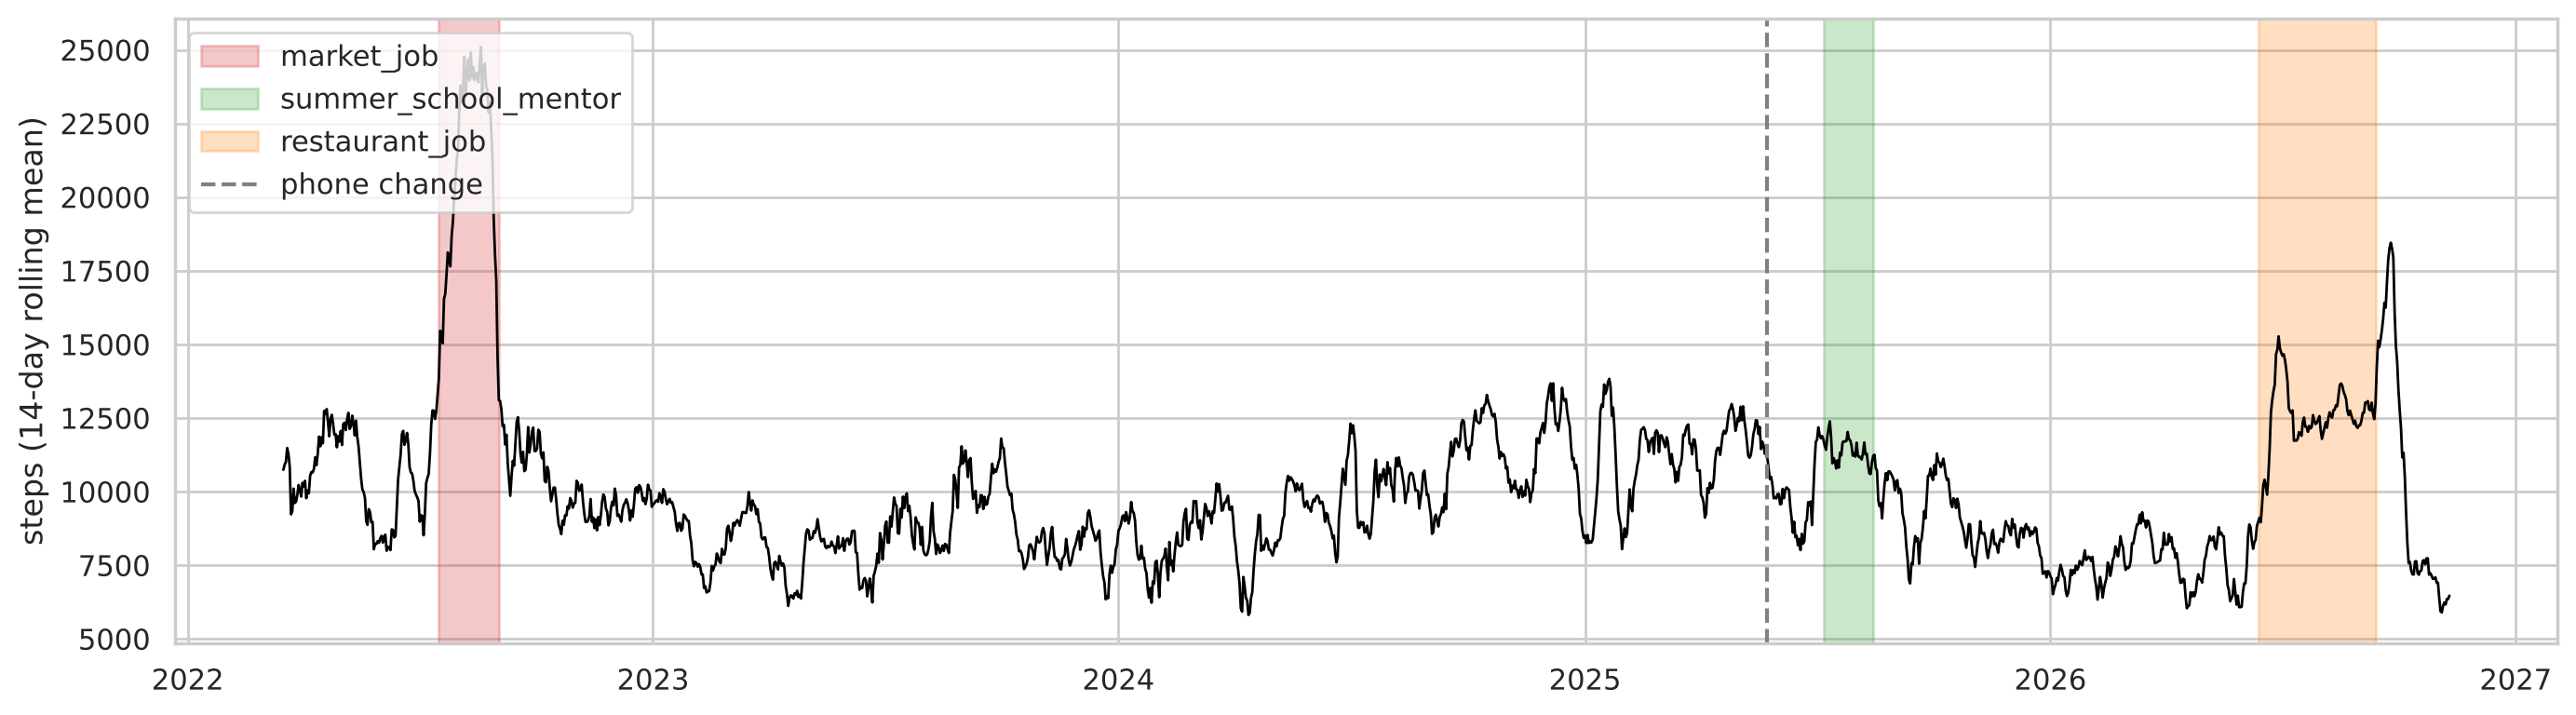

In [8]:
s = daily.set_index("date").steps.rolling(14, center=True).mean()
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(s.index, s.values, color="black", lw=1)
for p, c in zip(JOBS, ["tab:red","tab:green","tab:orange"]):
    d = daily[daily.period==p]
    ax.axvspan(d.date.min(), d.date.max(), color=c, alpha=.25, label=p)
ax.axvline(pd.Timestamp("2025-05-24"), ls="--", color="gray", label="phone change")
ax.set_ylabel("steps (14-day rolling mean)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG/"03_timeline.png", dpi=150); plt.show()

## 5. The shape of the day – hourly profiles

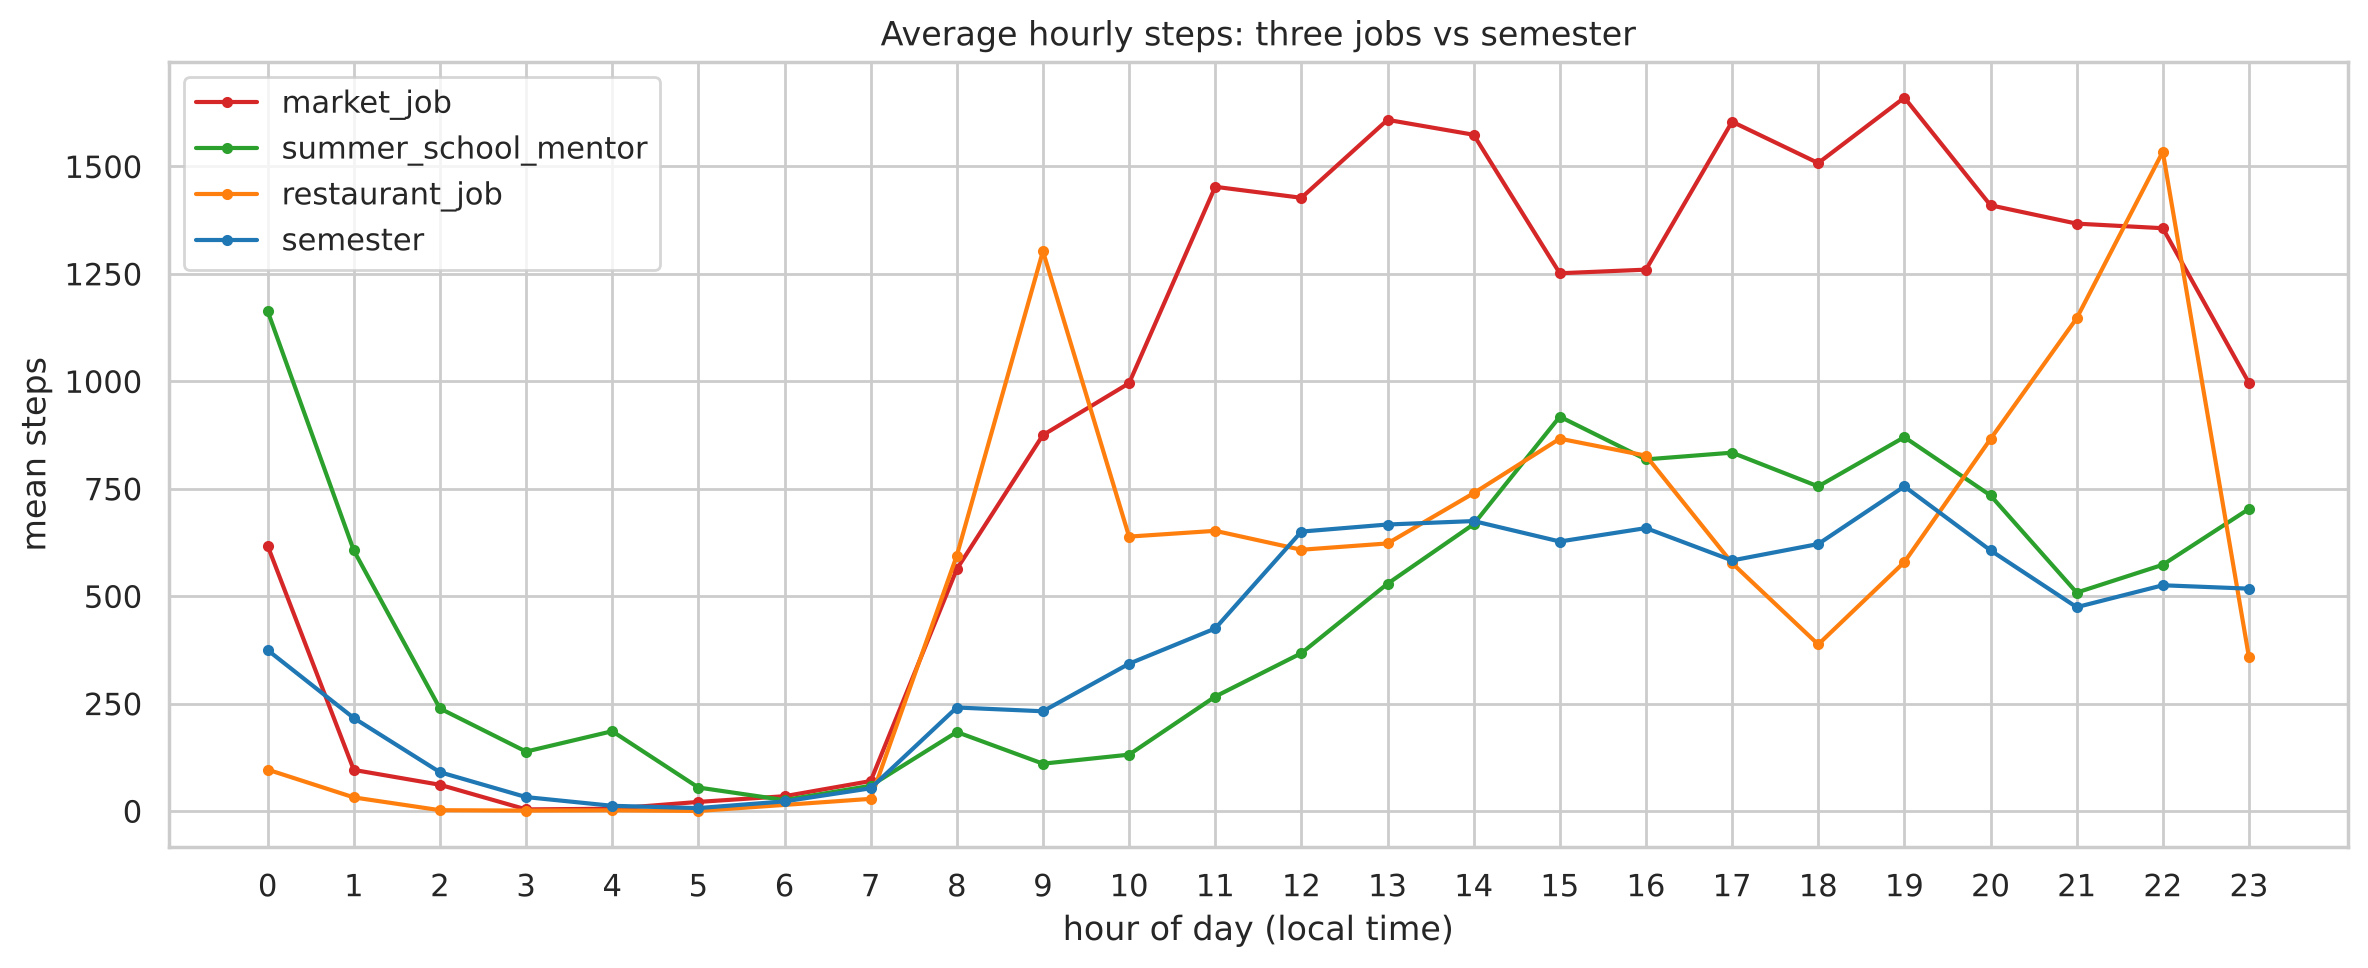

In [9]:
h = hourly.merge(daily[["date","period"]], on="date")
prof = (h.groupby(["period","hour"]).steps.sum()
          / h.groupby("period").date.nunique()).rename("steps").reset_index()
plt.figure(figsize=(12,5))
for p, c in zip(JOBS+["semester"], ["tab:red","tab:green","tab:orange","tab:blue"]):
    d = prof[prof.period==p]; plt.plot(d.hour, d.steps, marker="o", ms=3, label=p, color=c)
plt.xticks(range(0,24)); plt.xlabel("hour of day (local time)"); plt.ylabel("mean steps")
plt.title("Average hourly steps: three jobs vs semester"); plt.legend()
plt.tight_layout(); plt.savefig(FIG/"04_hourly_profiles.png", dpi=150); plt.show()

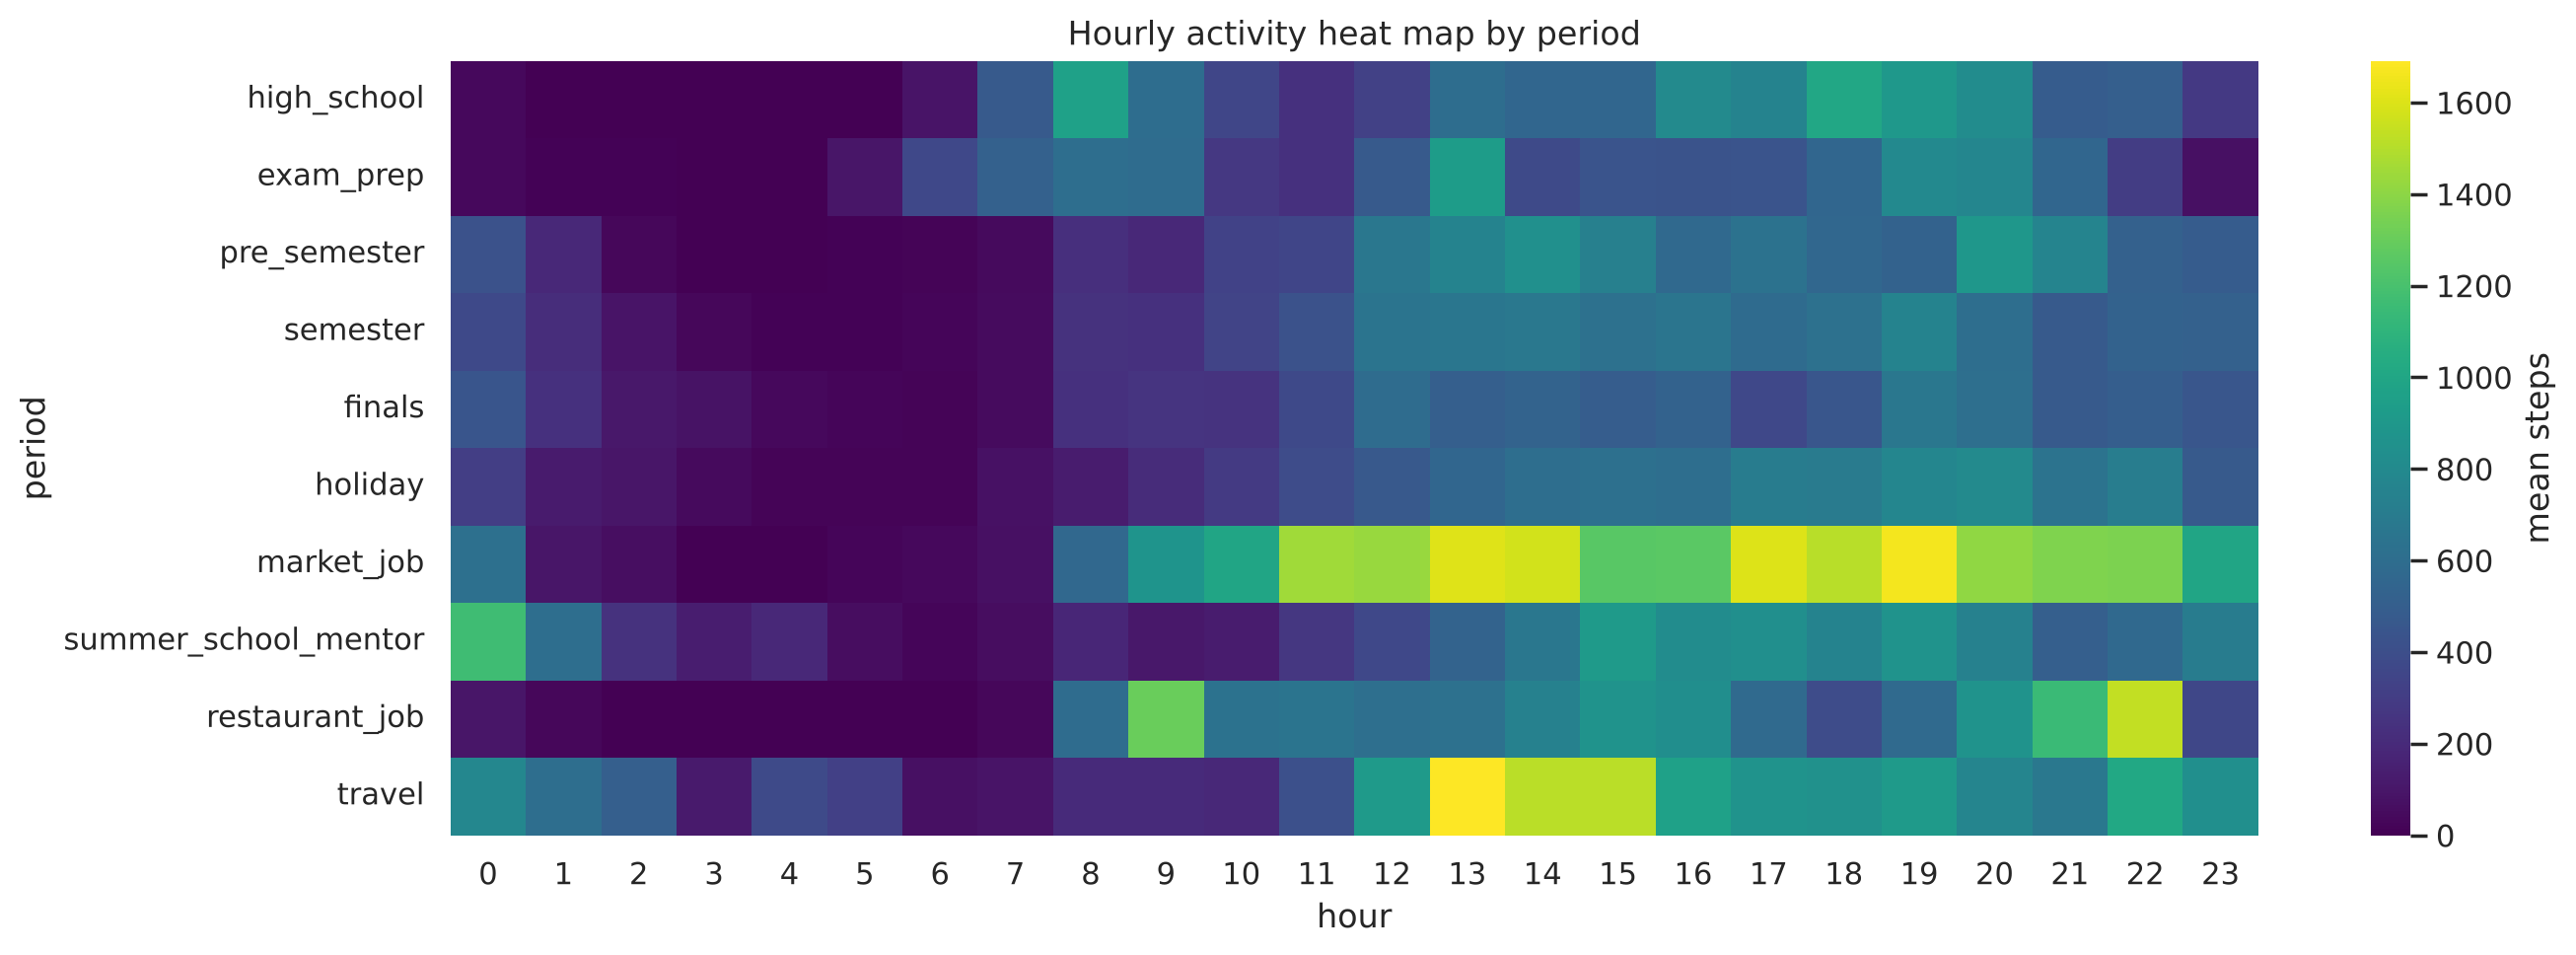

In [10]:
pv = prof.pivot(index="period", columns="hour", values="steps").reindex(ORDER).fillna(0)
plt.figure(figsize=(14,5)); sns.heatmap(pv, cmap="viridis", cbar_kws={"label":"mean steps"})
plt.title("Hourly activity heat map by period"); plt.tight_layout()
plt.savefig(FIG/"05_hourly_heatmap.png", dpi=150); plt.show()

Each job leaves a different "fingerprint": the peak hour and the width of the active
window differ, not only the total. This motivates the classification stage.

## 6. Weekday vs weekend

              weekday  weekend
period_group                  
break          9543.0   9033.0
school         9526.0   8619.0
travel        15462.0  20136.0
work          14774.0  14552.0


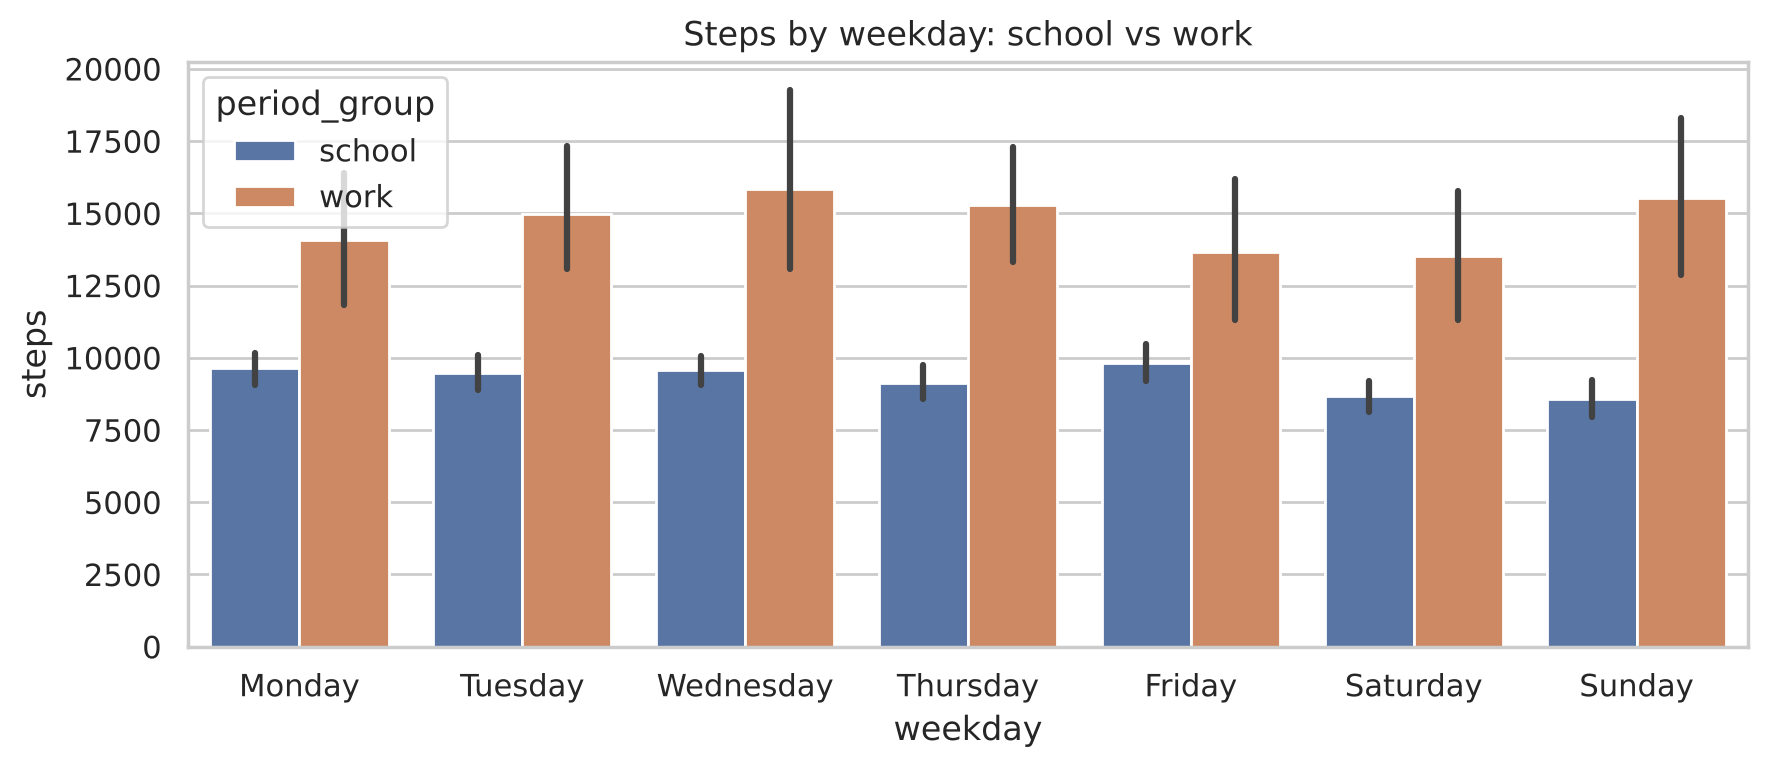

In [11]:
wk = daily.groupby(["period_group","is_weekend"]).steps.mean().unstack().round(0)
wk.columns = ["weekday","weekend"]; print(wk)
order_wd = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
plt.figure(figsize=(9,4))
sns.barplot(data=daily[daily.period_group.isin(["school","work"])], x="weekday", y="steps",
            hue="period_group", order=order_wd, errorbar=("ci",95))
plt.title("Steps by weekday: school vs work"); plt.tight_layout()
plt.savefig(FIG/"06_weekday.png", dpi=150); plt.show()

## 7. Correlations between daily variables

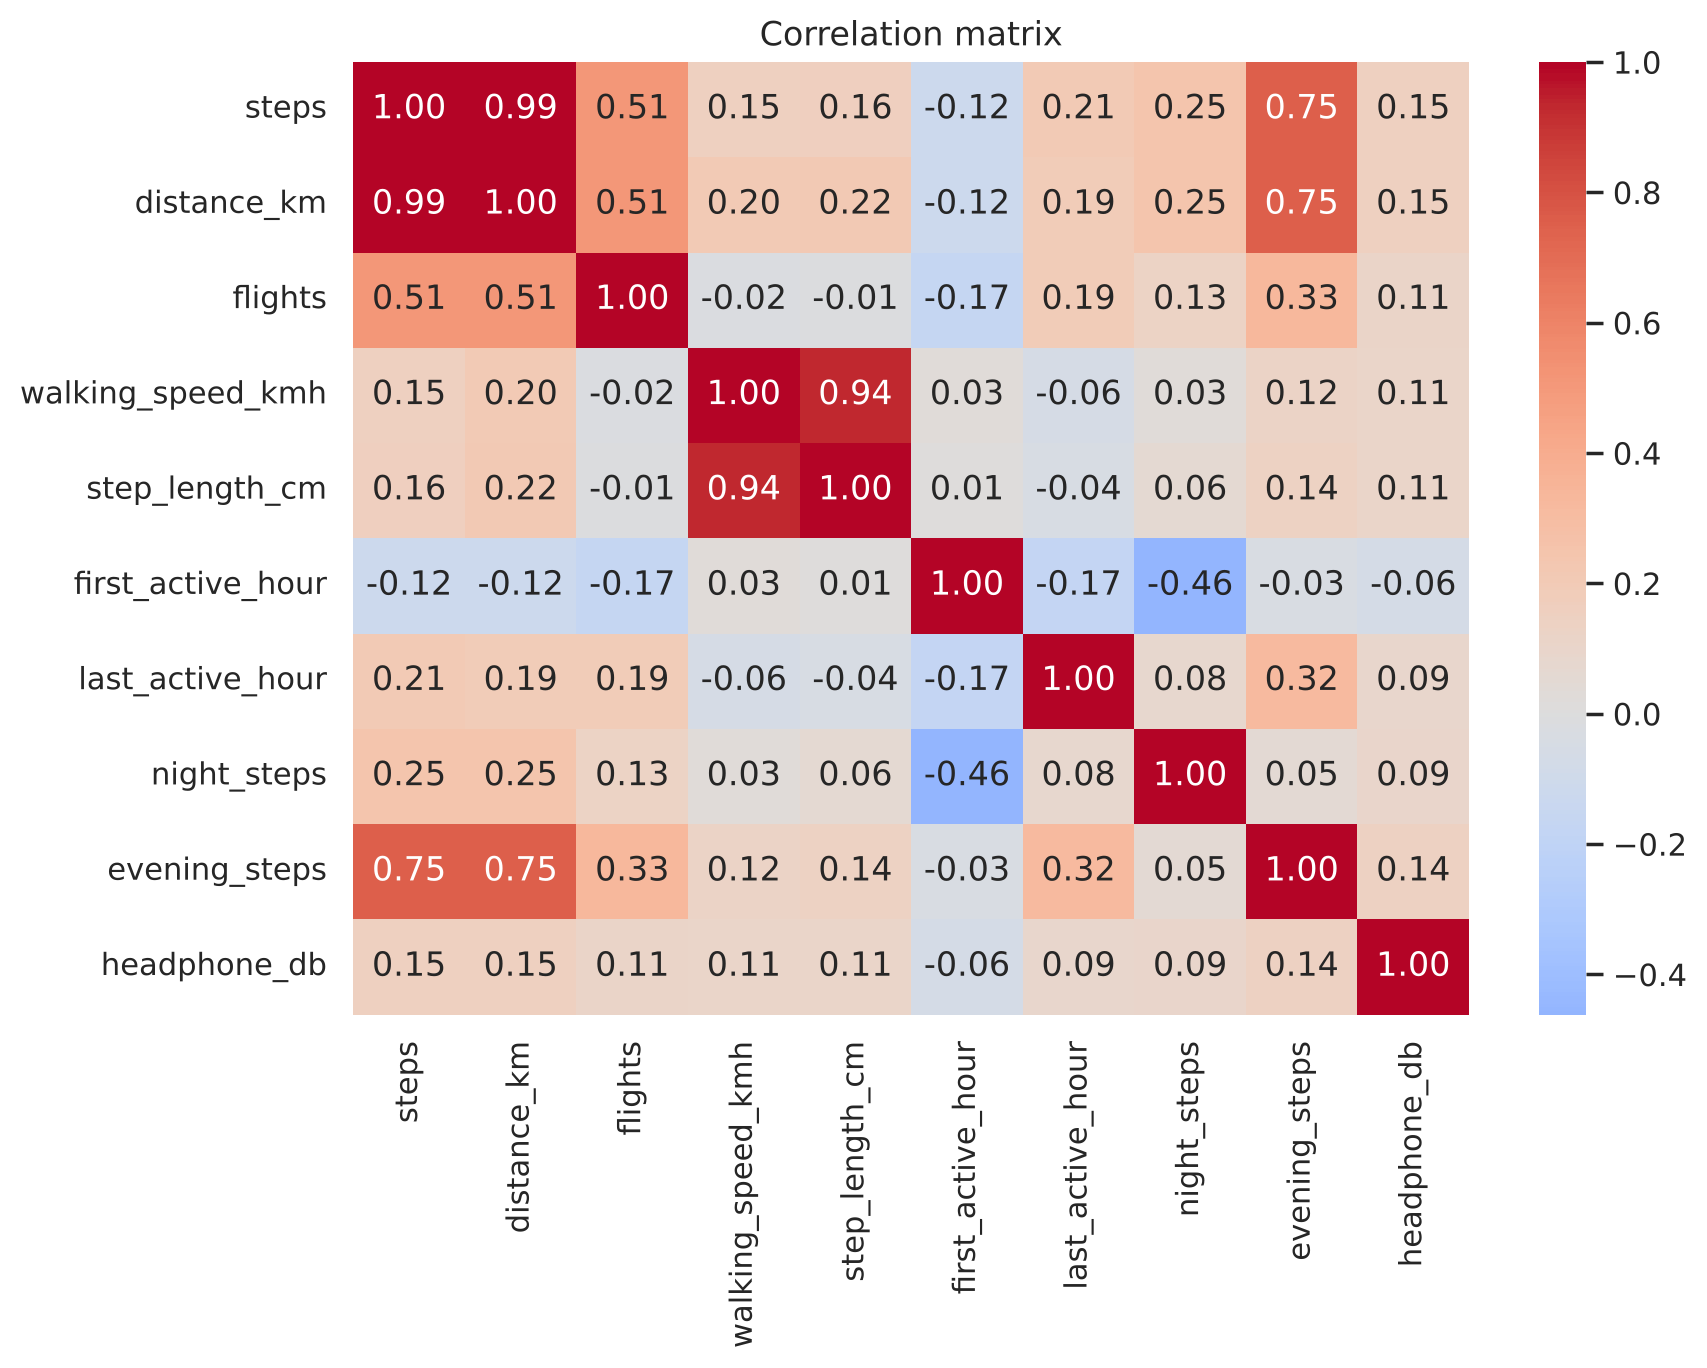

In [12]:
cols = ["steps","distance_km","flights","walking_speed_kmh","step_length_cm",
        "first_active_hour","last_active_hour","night_steps","evening_steps","headphone_db"]
plt.figure(figsize=(9,7))
sns.heatmap(daily[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout()
plt.savefig(FIG/"07_correlations.png", dpi=150); plt.show()

## 8. Device check: did the phone change shift the baseline?

In [13]:
sem = daily[daily.period=="semester"]
before, after = sem[sem.date<"2025-05-24"].steps, sem[sem.date>="2025-05-24"].steps
print(f"semester before change: n={len(before)}, mean={before.mean():.0f}")
print(f"semester after  change: n={len(after)}, mean={after.mean():.0f}")
print(f"difference: {after.mean()-before.mean():+.0f} steps/day")

semester before change: n=399, mean=10158
semester after  change: n=234, mean=8121
difference: -2037 steps/day


If this difference is small compared with the job-vs-semester differences, the device
change is unlikely to explain the main findings. It is tested formally in Stage 3.

## Key takeaways
- **Data quality is good:** 1,713 consecutive days, no gaps, no zero days; steps and distance correlate at r = 0.99.
- **Daily steps are right-skewed** (skewness 1.2), so non-parametric tests should be reported next to t-tests.
- **All three jobs are above every student period**, but very unequally: market job ≈ 21.8k, restaurant ≈ 12.5k, mentor ≈ 11.4k vs semester ≈ 9.4k steps/day.
- **Each job has its own daily shape:** the market job is high all day; the restaurant job has two peaks (≈ 9:00 and ≈ 22:00, i.e. the shifts) with a dip around 18:00; mentoring shifts activity late into the night (peak after midnight).
- **Weekends only matter at school** (≈ 900 fewer steps); at work, weekdays and weekends look the same.
- ⚠️ **Device change is a real confounder:** semester days after the May 2025 phone change average ≈ 2,000 fewer steps than before. Comparisons between the 2022 market job and the 2026 restaurant job must account for this (e.g. compare each job with *semester days measured by the same phone*).

Next: **Stage 3 – hypothesis testing.**